## On/off definition

Plots of dθ vs time. The computed thrust signal is overlaid in black.

The thrust is used to define the ON/OFF states. 

Figures are saved to the project `figures/` directory and to `on_off/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
#from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

In [3]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("on_off"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


#### Import data:

In [4]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3, 4]


In [5]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [6]:
#fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[16, 17, 18, 19, 20]


In [7]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [8]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [9]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [10]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 28, 30, 34, 34]


Load:

In [11]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [12]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [14]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [15]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [16]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [17]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/21 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/21 [00:03<01:01,  3.08s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|▉         | 2/21 [00:06<00:56,  2.99s/it]

...

 90%|█████████ | 19/21 [00:58<00:06,  3.02s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 20/21 [01:00<00:02,  2.92s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 21/21 [01:03<00:00,  3.03s/it]


In [18]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/21 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/21 [00:03<01:06,  3.31s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|▉         | 2/21 [00:06<00:56,  2.98s/it]

...

 90%|█████████ | 19/21 [00:55<00:05,  2.79s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 20/21 [00:58<00:02,  2.76s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 21/21 [01:01<00:00,  2.91s/it]


In [19]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 21/21 [00:00<00:00, 131.60it/s]


Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


# start visualization

In [21]:
fish_ID = '13_30Oct24_3' #t_range=(370, 375)
fish_ID = '17_21May24_2' #t_range=(191.7,191.7+5)
fish_ID = '28_04May24_1' #t_range=(90.2, 95.2)

In [22]:
i=1

print(fish_ids[i])

13_30Oct24_3


13_30Oct24_3


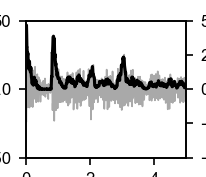

In [25]:
#fish_ID = '13_30Oct24_3' #t_range=(370, 375)
i=1
print(fish_ids[i])

dt=1/300
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(3.5 / 2.54, 3 / 2.54),dpi=150)


#----mean axis
ax.plot(t_c_list[i],dangletail_c_list[i], '-', color='darkgray', linewidth=0.8)
#ax.axvline(0, color='lightgray')
#ax.axhline(0, color='lightgray')

ax.set_ylabel(r'd$\theta$ (deg\s)')
ax.set_ylim(-50, 50)
ax.set_yticks([-50, 0, 50], [-50, 0.0, 50])

ax.set_xlabel("time (s)")
ax.set_xlim(370, 375)
ax.set_xticks([370, 372, 374], [0, 2, 4])

#-----right y-axis
ax_right = ax.twinx() 
color_2='black'
ax_right.plot(t_c_list[i],mean_thrust_c_list[i]*1000, color=color_2, label='thrust (mN)')
ax_right.set_ylabel("thrust (mN)")
#ax_right.set_yticks([0, 10, 20, 30]) 
ax_right.spines['right'].set_color(color_2)         # spine color
ax_right.yaxis.label.set_color(color_2)             # label color
ax_right.tick_params(axis='y', colors=color_2)      # tick color
ax_right.set_ylim(-50,50)
#ax_right.set_yticks([-40, -30, 0])
#ax_right.legend()

plt.savefig(os.path.join(path_media,f'Fig_1f_onoff_dtheta_thrust_young.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_1f_onoff_dtheta_thrust_young.pdf'),format = 'pdf')

plt.show()

In [26]:
i=1

print(fish_ids[i])

13_30Oct24_3


In [27]:
i=5
print(fish_ids[i])

17_21May24_2


18_22May24_2


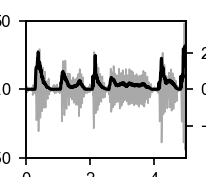

In [29]:
#fish_ID = '17_21May24_2' #t_range=(191.7,191.7+5)
i=7
print(fish_ids[i])

dt=1/300
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(3.5 / 2.54, 3 / 2.54),dpi=150)




#----mean axis
ax.plot(t_c_list[i],dangletail_c_list[i], '-', color='darkgray', linewidth=0.8)
#ax.axvline(0, color='lightgray')
#ax.axhline(0, color='lightgray')

ax.set_ylabel(r'd$\theta$ (deg\s)')
left_data = dangletail_c_list[i][(t_c_list[i] >= 90.2) & (t_c_list[i] <= 95.2)]
abs_max = np.nanmax(np.abs(left_data))
#ax.set_ylim(-abs_max, abs_max)
ax.set_ylim(-50, 50)
ax.set_yticks([-50, 0, 50], [-50, 0.0, 50])

ax.set_xlabel("time (s)")
start = 2001.7
ax.set_xlim(start,start+5)
ax.set_xticks([start, start+2, start+4], [0, 2, 4])

#-----right y-axis
ax_right = ax.twinx() 
color_2='black'
thrust_c = mean_thrust_c_list[i]*1000
ax_right.plot(t_c_list[i],thrust_c, color=color_2)

ax_right.set_ylabel("thrust (mN)")
#ax_right.set_yticks([0, 10, 20, 30]) 
ax_right.spines['right'].set_color(color_2)         # spine color
ax_right.yaxis.label.set_color(color_2)             # label color
ax_right.tick_params(axis='y', colors=color_2)      # tick color

right_data = thrust_c[(t_c_list[i] >= start) & (t_c_list[i] <= start+5)]
abs_max = np.nanmax(np.abs(right_data))
#ax_right.set_ylim(-abs_max, abs_max)
ax_right.set_ylim(-47, 47)
#ax_right.set_yticks([-40, -30, -20, 0])

plt.savefig(os.path.join(path_media,f'Fig_1f_onoff_dtheta_thrust_medium.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_1f_onoff_dtheta_thrust_medium.pdf'),format = 'pdf')

plt.show()

In [30]:
abs_max

29.911265622623176

abs_max

In [31]:
i=17
print(fish_ids[i])

28_04May24_1


28_04May24_1


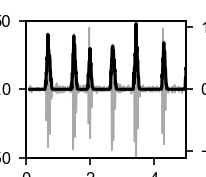

In [33]:
#ffish_ID = '28_04May24_1' #t_range=(90.2, 95.2)
i=17
print(fish_ids[i])

dt=1/300
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(3.5 / 2.54, 3 / 2.54),dpi=150)


#----mean axis
ax.plot(t_c_list[i],dangletail_c_list[i], '-', color='darkgray', linewidth=0.8)
#ax.axvline(0, color='lightgray')
#ax.axhline(0, color='lightgray')

ax.set_ylabel(r'd$\theta$ (deg\s)')
left_data = dangletail_c_list[i][(t_c_list[i] >= 90.2) & (t_c_list[i] <= 95.2)]
abs_max = np.nanmax(np.abs(left_data))
ax.set_ylim(-50, 50)
ax.set_yticks([-50, 0, 50], [-50, 0.0, 50])


ax.set_xlabel("time (s)")
ax.set_xlim(90.2, 95.2)
ax.set_xticks([90.2, 90.2+2, 90.2+4], [0, 2, 4])

#-----right y-axis
ax_right = ax.twinx() 
color_2='black'
thrust_c = mean_thrust_c_list[i]*1000
ax_right.plot(t_c_list[i],thrust_c, color=color_2)
ax_right.set_ylabel("thrust (mN)")
#ax_right.set_yticks([0, 10, 20, 30]) 
ax_right.spines['right'].set_color(color_2)         # spine color
ax_right.yaxis.label.set_color(color_2)             # label color
ax_right.tick_params(axis='y', colors=color_2)      # tick color
#ax_right.set_ylim(-50,50)

right_data = thrust_c[(t_c_list[i] >= 90.2) & (t_c_list[i] <= 95.2)]
abs_max = np.nanmax(np.abs(right_data))
ax_right.set_ylim(-1100, 1100)

#ax_right.set_yticks([-400, -300, -200, 0])


plt.savefig(os.path.join(path_media,f'Fig_1f_onoff_dtheta_thrust_old.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_1f_onoff_dtheta_thrust_old.pdf'),format = 'pdf')


plt.show()

28_04May24_1


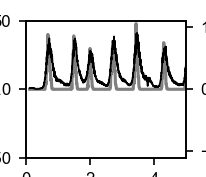

In [34]:
#ffish_ID = '28_04May24_1' #t_range=(90.2, 95.2)
i=17
print(fish_ids[i])

dt=1/300
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(3.5 / 2.54, 3 / 2.54),dpi=150)


#----mean axis
ax.plot(t_c_list[i],vfish_c_list[i], '-', color='black', linewidth=0.8)
#ax.axvline(0, color='lightgray')
#ax.axhline(0, color='lightgray')

ax.set_ylabel(r'$v_f$ (cm\s)')
left_data = dangletail_c_list[i][(t_c_list[i] >= 90.2) & (t_c_list[i] <= 95.2)]
abs_max = np.nanmax(np.abs(left_data))
ax.set_ylim(-50, 50)
ax.set_yticks([-50, 0, 50], [-50, 0.0, 50])


ax.set_xlabel("time (s)")
ax.set_xlim(90.2, 95.2)
ax.set_xticks([90.2, 90.2+2, 90.2+4], [0, 2, 4])

#-----right y-axis
ax_right = ax.twinx() 
color_2='black'
thrust_c = mean_thrust_c_list[i]*1000
ax_right.plot(t_c_list[i],thrust_c, color=color_2, alpha = 0.5)
ax_right.set_ylabel("thrust (mN)")
#ax_right.set_yticks([0, 10, 20, 30]) 
ax_right.spines['right'].set_color(color_2)         # spine color
ax_right.yaxis.label.set_color(color_2)             # label color
ax_right.tick_params(axis='y', colors=color_2)      # tick color
#ax_right.set_ylim(-50,50)

right_data = thrust_c[(t_c_list[i] >= 90.2) & (t_c_list[i] <= 95.2)]
abs_max = np.nanmax(np.abs(right_data))
ax_right.set_ylim(-1100, 1100)

#ax_right.set_yticks([-400, -300, -200, 0])

#fig.savefig(os.path.join(path_figures, "def_onoff_vfish_thrust_old.pdf"), format="pdf")


plt.show()